In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    average_precision_score
)

from xgboost import XGBClassifier

In [2]:
print("SHAP version:", shap.__version__)

SHAP version: 0.52.0


In [3]:
df = pd.read_csv("../data/raw/creditcard.csv")

print("Dataset shape:", df.shape)

Dataset shape: (284807, 31)


In [4]:
X = df.drop("Class", axis=1)
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [5]:
X_train = X_train.copy()
X_test = X_test.copy()

# Transaction hour
X_train["TransactionHour"] = (
    (X_train["Time"] // 3600) % 24
)

X_test["TransactionHour"] = (
    (X_test["Time"] // 3600) % 24
)

# Cyclical encoding
X_train["HourSin"] = np.sin(
    2 * np.pi * X_train["TransactionHour"] / 24
)

X_train["HourCos"] = np.cos(
    2 * np.pi * X_train["TransactionHour"] / 24
)

X_test["HourSin"] = np.sin(
    2 * np.pi * X_test["TransactionHour"] / 24
)

X_test["HourCos"] = np.cos(
    2 * np.pi * X_test["TransactionHour"] / 24
)

# Amount transformation
X_train["AmountLog"] = np.log1p(
    X_train["Amount"]
)

X_test["AmountLog"] = np.log1p(
    X_test["Amount"]
)

# Amount bucket
bins = [-1, 10, 50, 100, 500, 1000, np.inf]

X_train["AmountBucket"] = pd.cut(
    X_train["Amount"],
    bins=bins,
    labels=False
)

X_test["AmountBucket"] = pd.cut(
    X_test["Amount"],
    bins=bins,
    labels=False
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (227845, 35)
Testing shape: (56962, 35)


In [6]:
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_pos_weight = negative / positive

In [7]:
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)

In [8]:
xgb_model.fit(
    X_train,
    y_train
)

print("XGBoost trained successfully!")

XGBoost trained successfully!


In [9]:
y_prob = xgb_model.predict_proba(
    X_test
)[:, 1]

print(
    "ROC-AUC:",
    roc_auc_score(y_test, y_prob)
)

print(
    "PR-AUC:",
    average_precision_score(y_test, y_prob)
)

ROC-AUC: 0.9816354703811744
PR-AUC: 0.8528671148743486


In [10]:
explainer = shap.TreeExplainer(
    xgb_model
)

In [11]:
X_shap = X_test.sample(
    n=2000,
    random_state=42
)

In [12]:
shap_values = explainer(
    X_shap
)

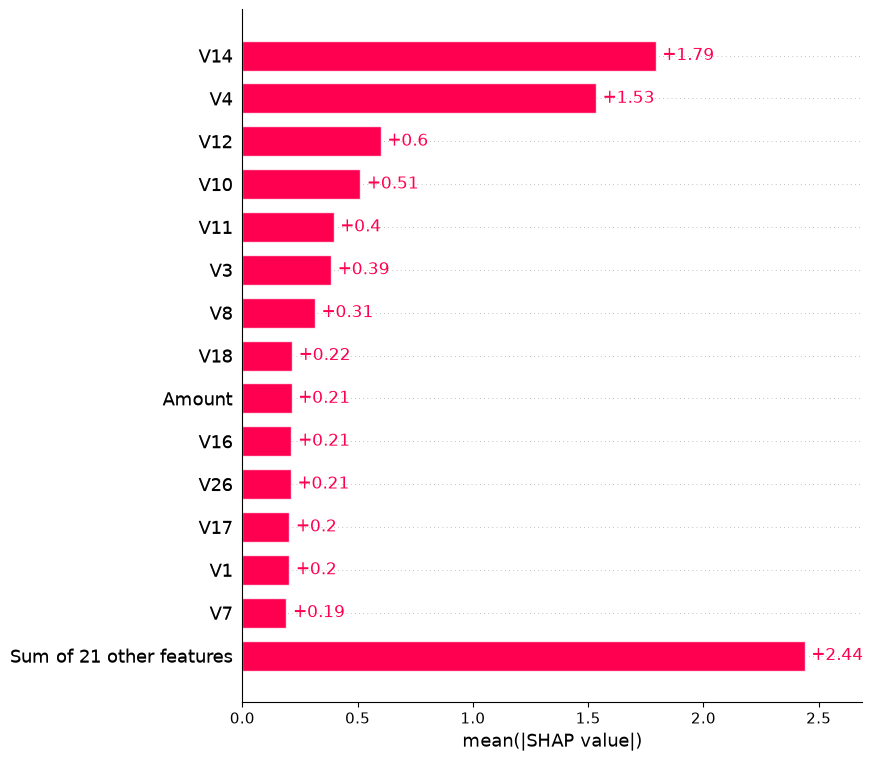

In [13]:
shap.plots.bar(
    shap_values,
    max_display=15
)

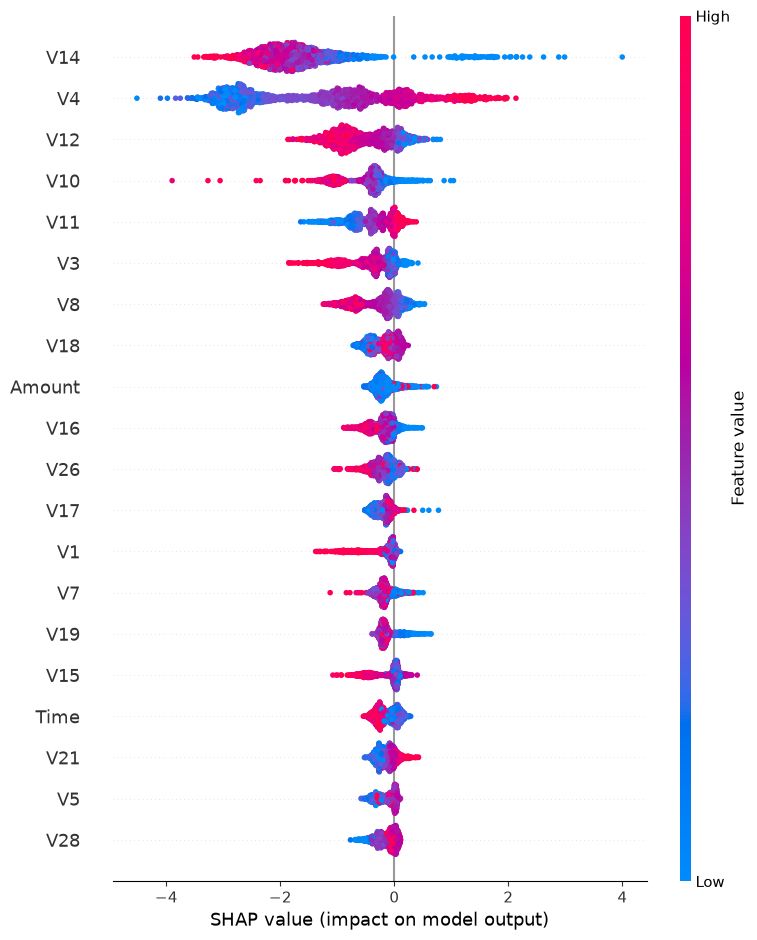

In [14]:
shap.summary_plot(
    shap_values,
    X_shap
)

In [15]:
transaction = X_test.iloc[[0]]

In [16]:
transaction_shap = explainer(
    transaction
)

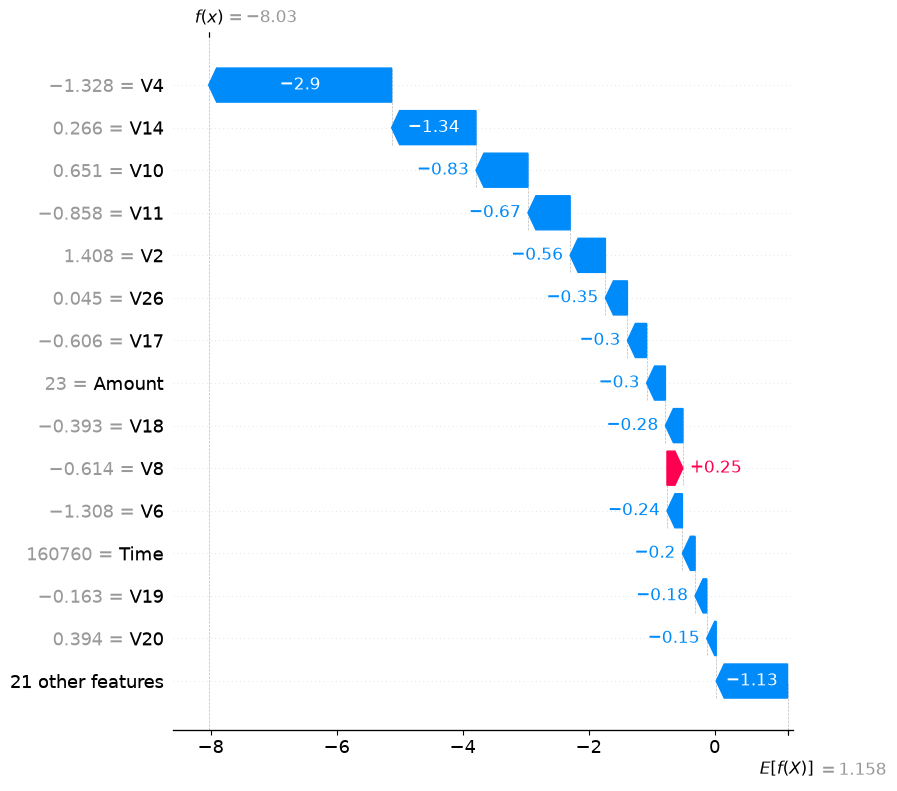

In [17]:
shap.plots.waterfall(
    transaction_shap[0],
    max_display=15
)

In [18]:
fraud_indices = y_test[
    y_test == 1
].index

In [19]:
fraud_index = fraud_indices[0]

In [22]:
fraud_transaction = X_test.loc[
    [fraud_index]
]

In [23]:
fraud_shap = explainer(
    fraud_transaction
)

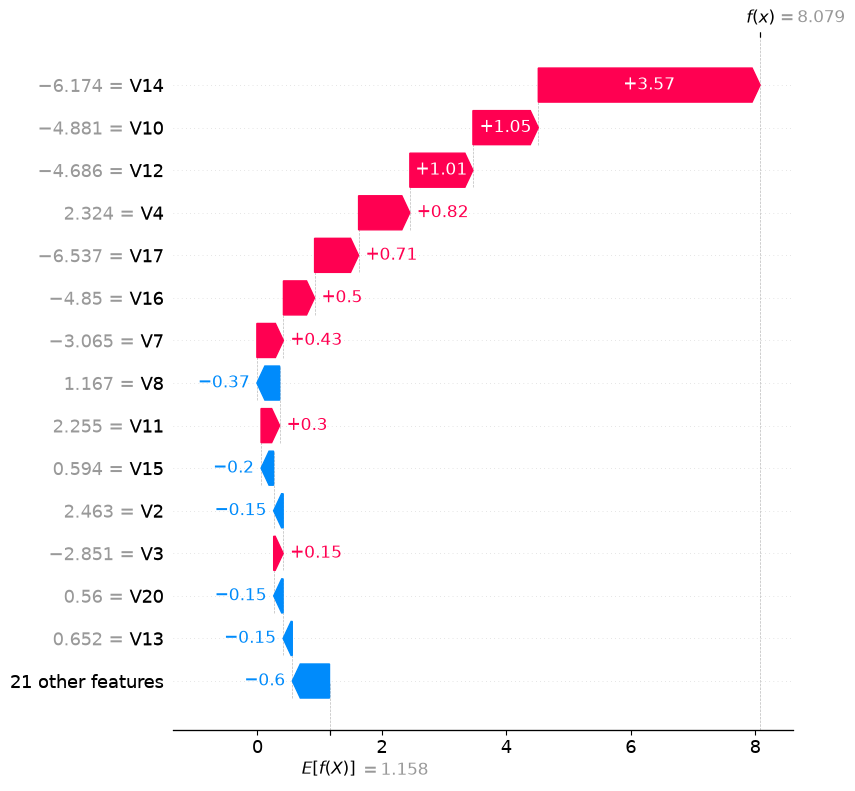

In [24]:
shap.plots.waterfall(
    fraud_shap[0],
    max_display=15
)

In [25]:
normal_indices = y_test[
    y_test == 0
].index

In [26]:
normal_index = normal_indices[0]

In [28]:
normal_transaction = X_test.loc[
    [normal_index]
]

normal_shap = explainer(
    normal_transaction
)

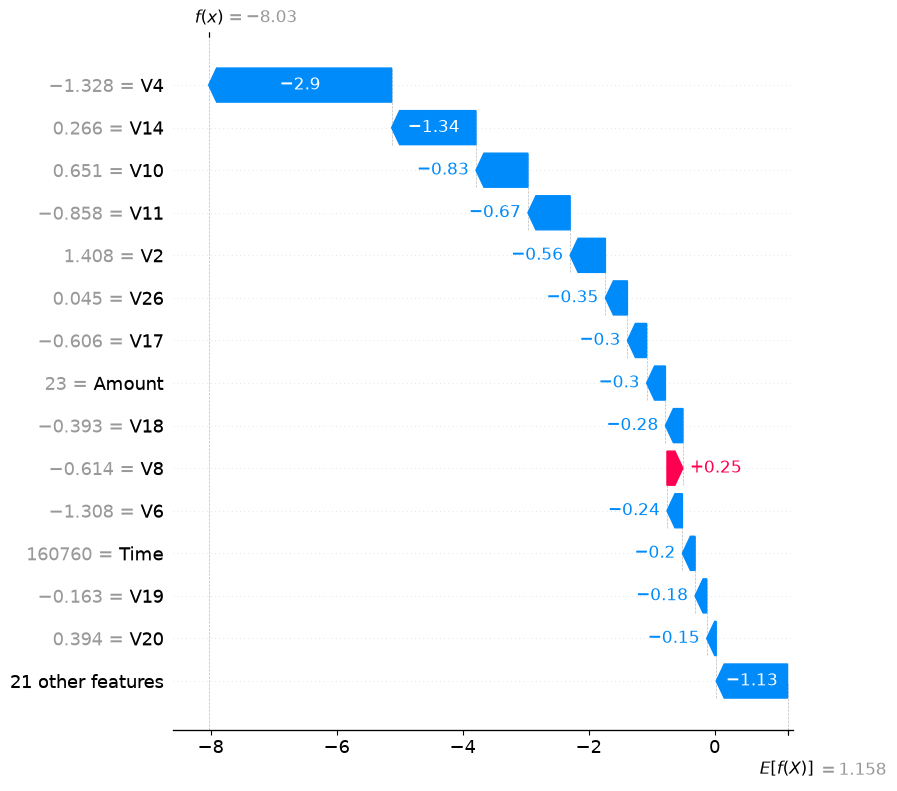

In [29]:
shap.plots.waterfall(
    normal_shap[0],
    max_display=15
)